In [42]:
from langgraph.graph import MessagesState
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
from langchain_core.messages import HumanMessage, RemoveMessage
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver

In [43]:
load_dotenv()

True

In [44]:
model = ChatOpenAI(model="gpt-4o-mini")

In [45]:
class ChatState(MessagesState):
    summary: str

In [46]:
def summarize_conversation(state: ChatState):

    existing_summary = state.get("summary", "")

    # Build summarization prompt
    if existing_summary:
        prompt = (
            f"Existing summary:\n{existing_summary}\n\n"
            "Extend the summary using the new conversation above."
        )
    else:
        prompt = "Summarize the conversation above."

    messages_for_summary = state["messages"] + [
        HumanMessage(content=prompt)
    ]

    response = model.invoke(messages_for_summary)

    # Keep only last 2 messages verbatim
    messages_to_delete = state["messages"][:-2]

    return {
        "summary": response.content,
        "messages": [RemoveMessage(id=m.id) for m in messages_to_delete],
    }

In [47]:
def chat_node(state: ChatState):
    messages = []

    summary = state.get("summary", "")

    if summary:
        messages.append({
            "role": "system",
            "content": f"Conversation summary:\n{summary}"
        })

    messages.extend(state["messages"])

    print(messages)

    response = model.invoke(messages)
    return {"messages": [response]}

In [48]:
def should_summarize(state: ChatState):
    return len(state["messages"]) > 6

In [49]:
builder = StateGraph(ChatState)

In [50]:
builder.add_node("chat", chat_node)
builder.add_node("summarize", summarize_conversation)

In [51]:
builder.add_edge(START, "chat")
builder.add_conditional_edges("chat", should_summarize, {True: "summarize", False: END})

In [52]:
checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)

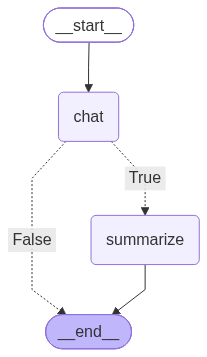

In [53]:
graph

In [54]:
config = {"configurable": {"thread_id": "t1"}}

def run_turn(text: str):
    # don't pass summary here: it has no reducer, so it would overwrite
    # the summary built up on previous turns with ""
    out = graph.invoke({"messages": [HumanMessage(content=text)]}, config=config)
    return out

In [55]:
# gives the current version of the state
def show_state():
    snap = graph.get_state(config)
    vals = snap.values
    print("\n--- STATE ---")
    print("summary:", vals.get("summary", ""))
    print("num_messages:", len(vals.get("messages", [])))
    print("messages:")
    for m in vals.get("messages", []):
        print("-", type(m).__name__, ":", m.content[:80])

In [56]:
run_turn('Quantum Physics')
show_state()

[HumanMessage(content='Quantum Physics', additional_kwargs={}, response_metadata={}, id='99b76f44-c316-4820-988c-35e36fc6c0fa')]

--- STATE ---
summary: 
num_messages: 2
messages:
- HumanMessage : Quantum Physics
- AIMessage : Quantum physics, or quantum mechanics, is a fundamental branch of physics that d


In [57]:
run_turn('How is Albert Einstien related?')
show_state()

[HumanMessage(content='Quantum Physics', additional_kwargs={}, response_metadata={}, id='99b76f44-c316-4820-988c-35e36fc6c0fa'), AIMessage(content='Quantum physics, or quantum mechanics, is a fundamental branch of physics that deals with the behavior of matter and energy at the smallest scales, typically at the level of atoms and subatomic particles. Here are some key concepts and principles within quantum physics:\n\n1. **Wave-Particle Duality**: Quantum objects exhibit both wave-like and particle-like properties. For example, light can behave like a wave (interference and diffraction) or like a particle (photons), depending on how it is observed.\n\n2. **Quantum Superposition**: Particles can exist in multiple states at once. A classic example is Schrödinger\'s cat thought experiment, where the cat is simultaneously alive and dead until observed.\n\n3. **Quantum Entanglement**: Particles can become correlated such that the state of one particle instantly affects the state of another,

In [58]:
run_turn('What are some of Einstien"s fampus work')
show_state()

[HumanMessage(content='Quantum Physics', additional_kwargs={}, response_metadata={}, id='99b76f44-c316-4820-988c-35e36fc6c0fa'), AIMessage(content='Quantum physics, or quantum mechanics, is a fundamental branch of physics that deals with the behavior of matter and energy at the smallest scales, typically at the level of atoms and subatomic particles. Here are some key concepts and principles within quantum physics:\n\n1. **Wave-Particle Duality**: Quantum objects exhibit both wave-like and particle-like properties. For example, light can behave like a wave (interference and diffraction) or like a particle (photons), depending on how it is observed.\n\n2. **Quantum Superposition**: Particles can exist in multiple states at once. A classic example is Schrödinger\'s cat thought experiment, where the cat is simultaneously alive and dead until observed.\n\n3. **Quantum Entanglement**: Particles can become correlated such that the state of one particle instantly affects the state of another,

In [59]:
run_turn('Explain special theory of relativity')
show_state()

[HumanMessage(content='Quantum Physics', additional_kwargs={}, response_metadata={}, id='99b76f44-c316-4820-988c-35e36fc6c0fa'), AIMessage(content='Quantum physics, or quantum mechanics, is a fundamental branch of physics that deals with the behavior of matter and energy at the smallest scales, typically at the level of atoms and subatomic particles. Here are some key concepts and principles within quantum physics:\n\n1. **Wave-Particle Duality**: Quantum objects exhibit both wave-like and particle-like properties. For example, light can behave like a wave (interference and diffraction) or like a particle (photons), depending on how it is observed.\n\n2. **Quantum Superposition**: Particles can exist in multiple states at once. A classic example is Schrödinger\'s cat thought experiment, where the cat is simultaneously alive and dead until observed.\n\n3. **Quantum Entanglement**: Particles can become correlated such that the state of one particle instantly affects the state of another,